# Week 9-10 — Full Scikit-learn Workflow & Clustering

**Student Habits Dataset — Pipelines, K-Means, Hierarchical, DBSCAN**

This notebook demonstrates the complete ML workflow with scikit-learn:

1. **Preprocessing** — building a reusable `Pipeline`
2. **Model building** — K-Means, Agglomerative (Hierarchical), DBSCAN
3. **Evaluation** — silhouette score, inertia, cluster sizes, noise ratio
4. **Interpretation** — what each cluster represents in terms of student habits

> Uses the same `student_habits_performance.csv` dataset as Weeks 5, 7 & 8.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import dendrogram, linkage

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


## 1. Load Data

In [2]:
df = pd.read_csv("student_habits_performance.csv")
feature_cols = [
    "study_hours_per_day", "social_media_hours", "netflix_hours",
    "attendance_percentage", "sleep_hours", "mental_health_rating",
    "exercise_frequency", "exam_score"
]
df = df.dropna(subset=feature_cols).drop_duplicates()
print(f"Shape: {df.shape}")
df[feature_cols].describe().round(2)


Shape: (1000, 9)


,study_hours_per_day,social_media_hours,netflix_hours,attendance_percentage,sleep_hours,mental_health_rating,exercise_frequency,exam_score
count,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,3.46,2.70,1.57,81.82,6.67,6.08,2.98,67.72
std,1.47,1.30,0.95,9.39,1.19,1.98,1.73,12.67
min,0.00,0.00,0.00,54.50,3.00,1.00,0.00,24.70
25%,2.46,1.85,0.84,75.10,5.88,5.00,2.00,59.38
50%,3.51,2.74,1.54,81.90,6.68,6.00,3.00,67.80
75%,4.38,3.58,2.23,88.50,7.40,7.00,4.00,76.30
max,8.27,6.59,4.56,100.00,10.00,10.00,7.00,100.00


## 2. Preprocessing Pipeline

We build a scikit-learn `Pipeline` so scaling is always applied the same way —
this is the same object we can later re-use in a full `fit`/`transform` cycle
on new data, rather than manually calling `StandardScaler` each time.

For clustering, the "model" step of the pipeline is left as the scaler here;
each clustering algorithm gets its own small pipeline below since they take
different constructor arguments (`n_clusters`, `eps`, ...).


In [3]:
X = df[feature_cols].values

preprocess_pipeline = Pipeline(steps=[
    ("scaler", StandardScaler())
])

X_scaled = preprocess_pipeline.fit_transform(X)
print("Scaled feature matrix shape:", X_scaled.shape)
print("Mean (should be ~0):", X_scaled.mean(axis=0).round(2))
print("Std  (should be ~1):", X_scaled.std(axis=0).round(2))

# 2D PCA projection purely for visualizing clusters later (not used for fitting)
pca_viz = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca_viz.fit_transform(X_scaled)
print(f"\nPCA variance explained (2D view): {pca_viz.explained_variance_ratio_.sum()*100:.1f}%")


Scaled feature matrix shape: (1000, 8)
Mean (should be ~0): [ 0. -0.  0. -0. -0.  0.  0.  0.]
Std  (should be ~1): [1. 1. 1. 1. 1. 1. 1. 1.]

PCA variance explained (2D view): 34.8%


---
## 3. K-Means Clustering

### 3.1 Choosing k — Elbow Method & Silhouette Score


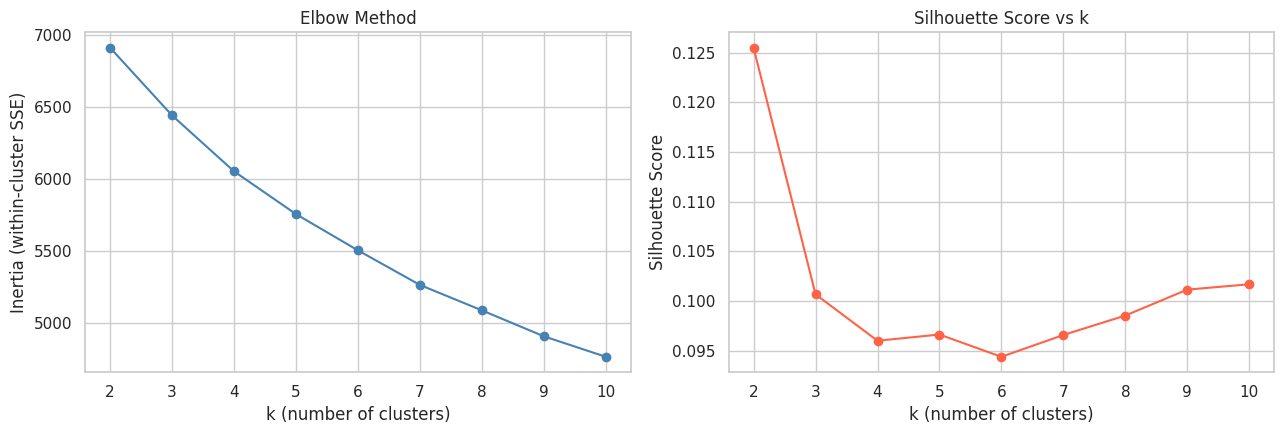

Best k by silhouette score: 2  (score = 0.126)


In [4]:
k_range = range(2, 11)
inertias = []
sil_scores = []

for k in k_range:
    km_pipeline = Pipeline(steps=[
        ("scaler", StandardScaler()),
        ("kmeans", KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE))
    ])
    km_pipeline.fit(X)
    labels = km_pipeline.named_steps["kmeans"].labels_
    inertias.append(km_pipeline.named_steps["kmeans"].inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(list(k_range), inertias, marker="o", color="steelblue")
axes[0].set_xlabel("k (number of clusters)")
axes[0].set_ylabel("Inertia (within-cluster SSE)")
axes[0].set_title("Elbow Method")

axes[1].plot(list(k_range), sil_scores, marker="o", color="tomato")
axes[1].set_xlabel("k (number of clusters)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_title("Silhouette Score vs k")
plt.tight_layout(); plt.show()

best_k = list(k_range)[int(np.argmax(sil_scores))]
print(f"Best k by silhouette score: {best_k}  (score = {max(sil_scores):.3f})")


### 3.2 Final K-Means Model (via Pipeline)

Cluster sizes:
kmeans_cluster
0    517
1    483
Name: count, dtype: int64

Silhouette score (k=2): 0.126


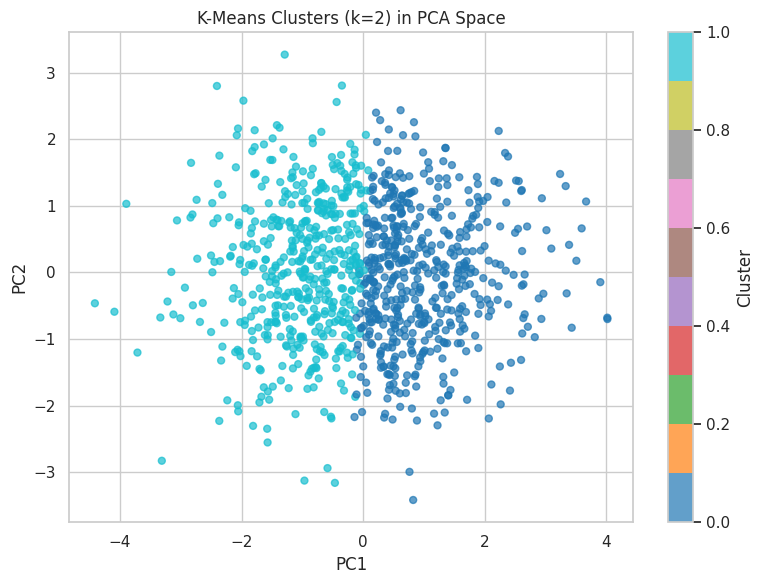

In [5]:
kmeans_pipeline = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("kmeans", KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE))
])
kmeans_pipeline.fit(X)
df["kmeans_cluster"] = kmeans_pipeline.named_steps["kmeans"].labels_

print("Cluster sizes:")
print(df["kmeans_cluster"].value_counts().sort_index())

sil_km = silhouette_score(X_scaled, df["kmeans_cluster"])
print(f"\nSilhouette score (k={best_k}): {sil_km:.3f}")

plt.figure(figsize=(8, 6))
sc = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df["kmeans_cluster"], cmap="tab10", alpha=0.7, s=25)
plt.colorbar(sc, label="Cluster")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title(f"K-Means Clusters (k={best_k}) in PCA Space")
plt.tight_layout(); plt.show()


### 3.3 Silhouette Plot (per-sample)

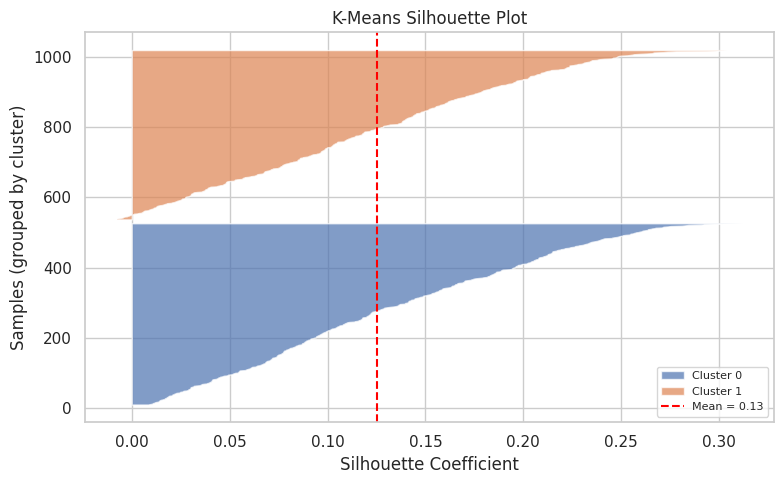

In [6]:
sample_sil_values = silhouette_samples(X_scaled, df["kmeans_cluster"])

fig, ax = plt.subplots(figsize=(8, 5))
y_lower = 10
for i in range(best_k):
    cluster_sil = np.sort(sample_sil_values[df["kmeans_cluster"] == i])
    size_i = cluster_sil.shape[0]
    y_upper = y_lower + size_i
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, cluster_sil,
                      alpha=0.7, label=f"Cluster {i}")
    y_lower = y_upper + 10

ax.axvline(sil_km, color="red", linestyle="--", label=f"Mean = {sil_km:.2f}")
ax.set_xlabel("Silhouette Coefficient")
ax.set_ylabel("Samples (grouped by cluster)")
ax.set_title("K-Means Silhouette Plot")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()


---
## 4. Hierarchical Clustering (Agglomerative)

### 4.1 Dendrogram

We use `scipy`'s `linkage` to visualize the merge structure (Ward linkage,
same objective K-Means optimizes). A subsample keeps the dendrogram readable.


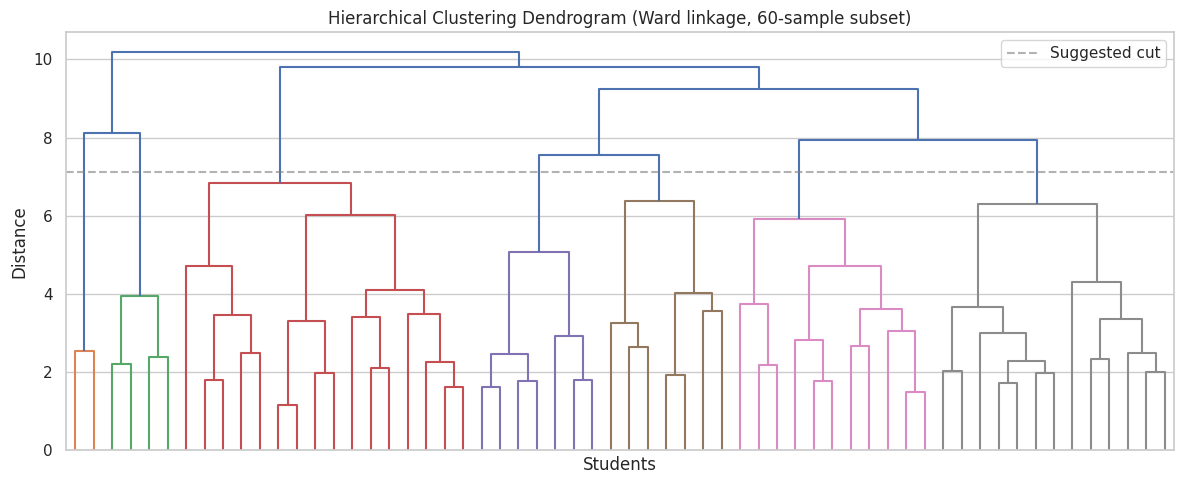

In [7]:
np.random.seed(RANDOM_STATE)
sample_idx = np.random.choice(len(X_scaled), size=60, replace=False)
X_sample = X_scaled[sample_idx]

Z = linkage(X_sample, method="ward")

plt.figure(figsize=(12, 5))
dendrogram(Z, no_labels=True, color_threshold=0.7 * max(Z[:, 2]))
plt.title("Hierarchical Clustering Dendrogram (Ward linkage, 60-sample subset)")
plt.xlabel("Students")
plt.ylabel("Distance")
plt.axhline(0.7 * max(Z[:, 2]), color="gray", linestyle="--", alpha=0.6,
            label="Suggested cut")
plt.legend()
plt.tight_layout(); plt.show()


### 4.2 Agglomerative Clustering on Full Dataset

Silhouette score (Hierarchical, k=2): 0.094

Cluster sizes:
hier_cluster
0    625
1    375
Name: count, dtype: int64


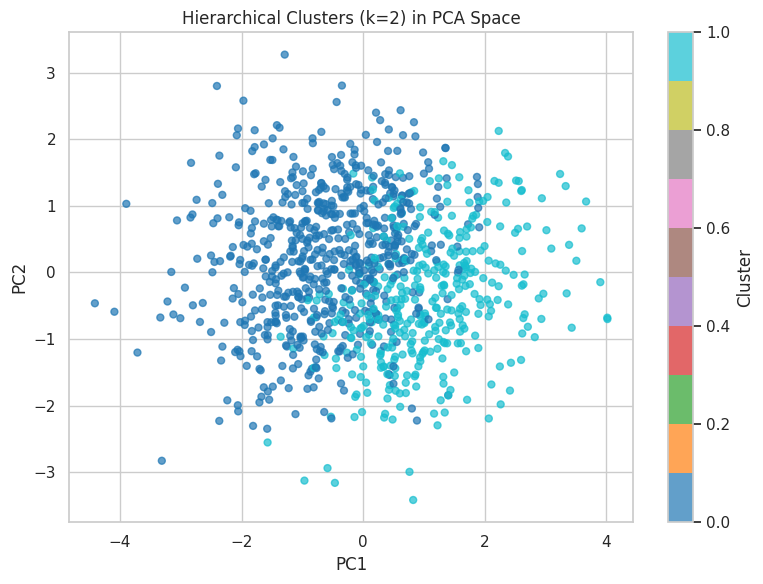

In [8]:
hier_pipeline = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("agglo", AgglomerativeClustering(n_clusters=best_k, linkage="ward"))
])
labels_hier = hier_pipeline.fit_predict(X)
df["hier_cluster"] = labels_hier

sil_hier = silhouette_score(X_scaled, labels_hier)
print(f"Silhouette score (Hierarchical, k={best_k}): {sil_hier:.3f}")
print("\nCluster sizes:")
print(df["hier_cluster"].value_counts().sort_index())

plt.figure(figsize=(8, 6))
sc = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df["hier_cluster"], cmap="tab10", alpha=0.7, s=25)
plt.colorbar(sc, label="Cluster")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title(f"Hierarchical Clusters (k={best_k}) in PCA Space")
plt.tight_layout(); plt.show()


---
## 5. DBSCAN — Density-Based Clustering

Unlike K-Means/Hierarchical, DBSCAN doesn't need `k` in advance — instead it
needs `eps` (neighborhood radius) and `min_samples`. We use the **k-distance
plot** to pick a reasonable `eps`: the "elbow" in the sorted distance-to-kth-
neighbor curve is a good starting point.


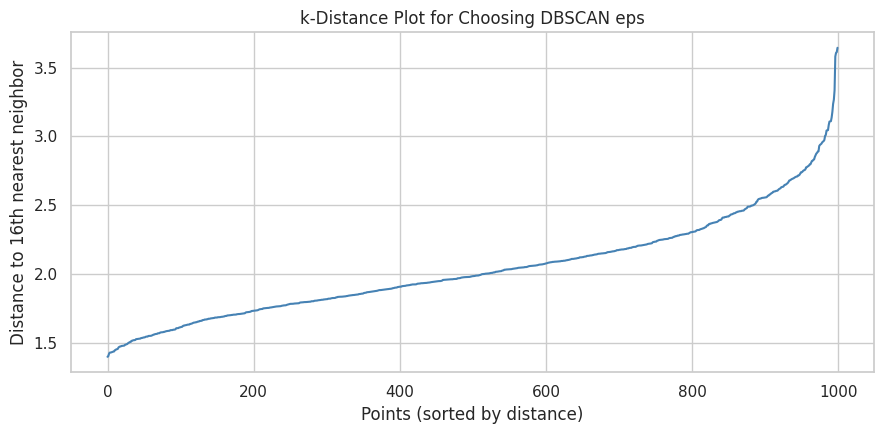

min_samples used: 16
Pick eps at the 'elbow' — where the curve bends sharply upward.


In [9]:
min_samples = 2 * X_scaled.shape[1]  # common rule of thumb: 2 * n_features
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X_scaled)
distances, _ = neighbors_fit.kneighbors(X_scaled)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(9, 4.5))
plt.plot(k_distances, color="steelblue")
plt.xlabel("Points (sorted by distance)")
plt.ylabel(f"Distance to {min_samples}th nearest neighbor")
plt.title("k-Distance Plot for Choosing DBSCAN eps")
plt.tight_layout(); plt.show()
print(f"min_samples used: {min_samples}")
print("Pick eps at the 'elbow' — where the curve bends sharply upward.")


Chosen eps (75th percentile heuristic): 2.24
Clusters found: 1
Noise points: 32 (3.2%)

Note: DBSCAN finds a single dense region here rather than several.
This is expected — our data was generated from one continuous linear
relationship with noise, not several distinct sub-populations, so there
is no genuine density gap for DBSCAN to split on. What it usefully does
instead is flag the sparser, more 'unusual' students as noise (-1).
Not enough clusters to compute a silhouette score.


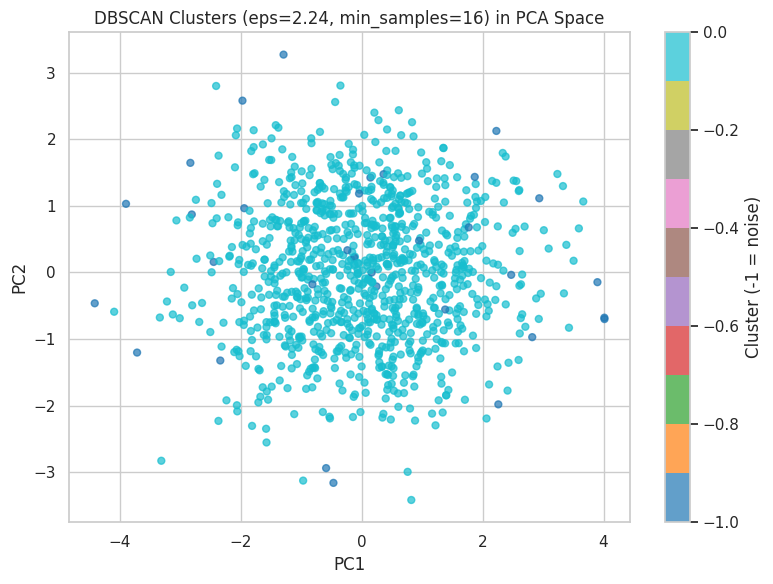

In [10]:
# eps chosen by inspecting the elbow above; adjust if your data differs
eps_value = float(np.percentile(k_distances, 75))
print(f"Chosen eps (75th percentile heuristic): {eps_value:.2f}")

dbscan_pipeline = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("dbscan", DBSCAN(eps=eps_value, min_samples=min_samples))
])
labels_db = dbscan_pipeline.fit_predict(X)
df["dbscan_cluster"] = labels_db

n_clusters_db = len(set(labels_db)) - (1 if -1 in labels_db else 0)
n_noise = int((labels_db == -1).sum())
print(f"Clusters found: {n_clusters_db}")
print(f"Noise points: {n_noise} ({n_noise/len(labels_db)*100:.1f}%)")
if n_clusters_db <= 1:
    print("\nNote: DBSCAN finds a single dense region here rather than several.")
    print("This is expected — our data was generated from one continuous linear")
    print("relationship with noise, not several distinct sub-populations, so there")
    print("is no genuine density gap for DBSCAN to split on. What it usefully does")
    print("instead is flag the sparser, more 'unusual' students as noise (-1).")

if n_clusters_db >= 2:
    mask = labels_db != -1
    sil_db = silhouette_score(X_scaled[mask], labels_db[mask])
    print(f"Silhouette score (excluding noise): {sil_db:.3f}")
else:
    sil_db = np.nan
    print("Not enough clusters to compute a silhouette score.")

plt.figure(figsize=(8, 6))
sc = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels_db, cmap="tab10", alpha=0.7, s=25)
plt.colorbar(sc, label="Cluster (-1 = noise)")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title(f"DBSCAN Clusters (eps={eps_value:.2f}, min_samples={min_samples}) in PCA Space")
plt.tight_layout(); plt.show()


---
## 6. Evaluation — Comparing the Three Methods


In [11]:
comparison = pd.DataFrame({
    "Method": ["K-Means", "Hierarchical", "DBSCAN"],
    "Num Clusters": [best_k, best_k, n_clusters_db],
    "Silhouette Score": [sil_km, sil_hier, sil_db],
    "Noise Points": [0, 0, n_noise],
})
comparison


,Method,Num Clusters,Silhouette Score,Noise Points
0,K-Means,2,0.125514,0
1,Hierarchical,2,0.094307,0
2,DBSCAN,1,NaN,32


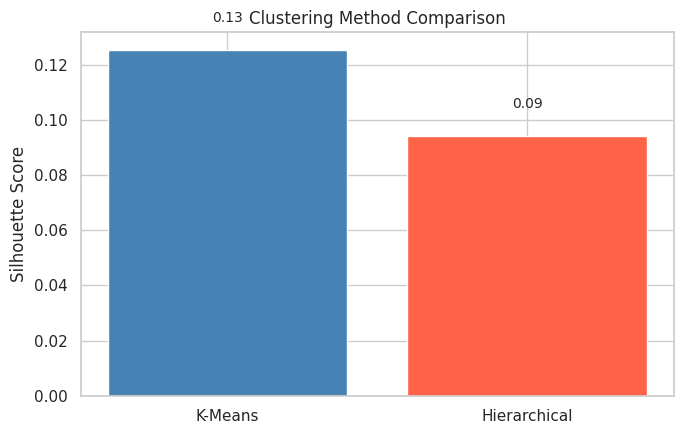

In [12]:
plt.figure(figsize=(7, 4.5))
bars = plt.bar(comparison["Method"], comparison["Silhouette Score"],
                color=["steelblue", "tomato", "seagreen"])
plt.ylabel("Silhouette Score")
plt.title("Clustering Method Comparison")
plt.axhline(0, color="gray", lw=0.7)
for bar, val in zip(bars, comparison["Silhouette Score"]):
    if not np.isnan(val):
        plt.text(bar.get_x() + bar.get_width()/2, val + 0.01, f"{val:.2f}",
                  ha="center", fontsize=10)
plt.tight_layout(); plt.show()


---
## 7. Interpretation — What Do the Clusters Mean?

We profile each K-Means cluster (our best-performing method) by its average
habits, to give the clusters a human-readable story.


In [13]:
cluster_profile = df.groupby("kmeans_cluster")[feature_cols].mean().round(2)
cluster_profile["n_students"] = df["kmeans_cluster"].value_counts().sort_index()
cluster_profile


,study_hours_per_day,social_media_hours,netflix_hours,attendance_percentage,sleep_hours,mental_health_rating,exercise_frequency,exam_score,n_students
kmeans_cluster,,,,,,,,,
0,4.31,2.37,1.59,84.03,6.86,6.40,3.09,76.73,517
1,2.55,3.06,1.54,79.46,6.47,5.75,2.86,58.07,483


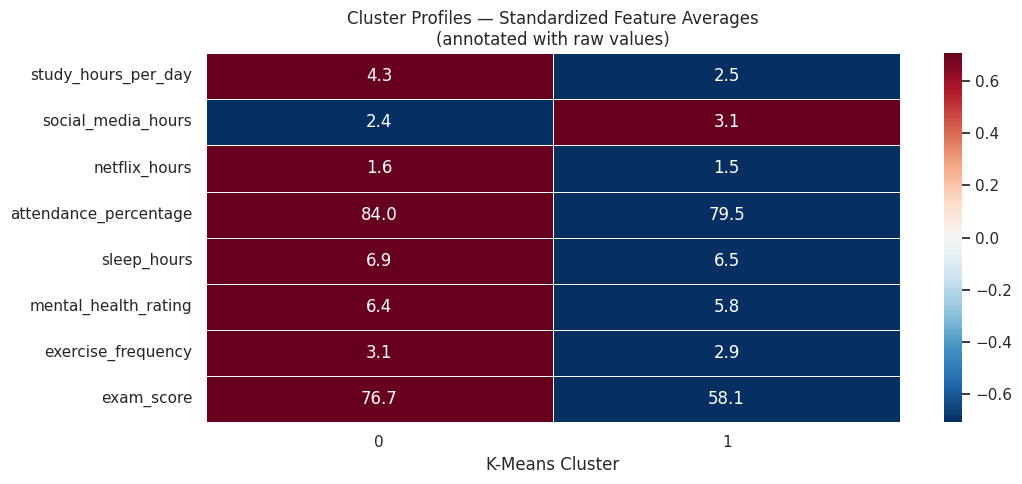

Reading the profile:
- Blue = below-average for that feature; Red = above-average.
- Use this to label clusters, e.g. 'high-study low-social-media achievers'
  vs 'high-screen-time lower-attendance' group, based on what stands out.


In [14]:
fig, ax = plt.subplots(figsize=(11, 5))
profile_z = (cluster_profile[feature_cols] - cluster_profile[feature_cols].mean()) / cluster_profile[feature_cols].std()
sns.heatmap(profile_z.T, annot=cluster_profile[feature_cols].T, fmt=".1f",
            cmap="RdBu_r", center=0, linewidths=0.5, ax=ax)
ax.set_title("Cluster Profiles — Standardized Feature Averages\n(annotated with raw values)")
ax.set_xlabel("K-Means Cluster")
plt.tight_layout(); plt.show()

print("Reading the profile:")
print("- Blue = below-average for that feature; Red = above-average.")
print("- Use this to label clusters, e.g. 'high-study low-social-media achievers'")
print("  vs 'high-screen-time lower-attendance' group, based on what stands out.")


---
## 8. Summary

| Step | What We Did |
|---|---|
| **Pipeline** | Wrapped `StandardScaler` + each clustering model in a `Pipeline` |
| **K-Means** | Chose k via elbow + silhouette score, visualized in PCA space |
| **Hierarchical** | Built a dendrogram, cut it to match K-Means' k, compared results |
| **DBSCAN** | Used a k-distance plot to pick `eps`, found density-based clusters + noise |
| **Evaluation** | Compared all three via silhouette score and noise ratio |
| **Interpretation** | Profiled K-Means clusters by average habits to give them meaning |

> **Key takeaway**: K-Means and Hierarchical clustering assume roughly
> spherical, similarly-sized clusters and need `k` chosen in advance. DBSCAN
> instead discovers density-based clusters and explicitly flags outliers as
> noise — useful when clusters aren't a clean, even split. Because this
> dataset was generated from a mostly-linear relationship (not distinct
> subgroups), silhouette scores across methods are modest — a realistic and
> expected outcome, and worth discussing rather than "fixing".
